In [3]:
# Import pustaka
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from google.colab import files

In [4]:
file_terunggah = files.upload()
nama_file = list(file_terunggah.keys())[0]
print("File berhasil diunggah:")
print(nama_file)

Saving dataset_kelulusan.xlsx to dataset_kelulusan.xlsx
File berhasil diunggah:
dataset_kelulusan.xlsx


In [ ]:
# Memuat data dari file Excel yang diunggah ke dalam DataFrame
df = pd.read_excel(nama_file)
print("Data berhasil dimuat ke dalam variabel 'df'.")
display(df.head())

In [6]:
# Membaca dataset dari file Excel yang diunggah ke dalam DataFrame
df = pd.read_excel(nama_file)
print("Data berhasil dimuat ke dalam variabel 'df'.\n")

# Pemeriksaan dan Informasi Dataset
print("=== INFORMASI DATASET ===")
df.info()

print("\n=== PEMERIKSAAN MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== DISTRIBUSI TARGET (STATUS LULUS) ===")
if 'Status_Lulus' in df.columns:
    print(df['Status_Lulus'].value_counts())
else:
    print("Kolom 'Status_Lulus' tidak ditemukan. Kolom yang tersedia:", df.columns.tolist())

print("\n=== STATISTIK DESKRIPTIF FITUR ===")
display(df.describe())

Data berhasil dimuat ke dalam variabel 'df'.

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Siswa_ID              200 non-null    object
 1   Nilai_Tugas           200 non-null    int64 
 2   Nilai_UTS             200 non-null    int64 
 3   Nilai_UAS             200 non-null    int64 
 4   Persentase_Kehadiran  200 non-null    int64 
 5   Jumlah_Absen          200 non-null    int64 
 6   Status_Lulus          200 non-null    object
dtypes: int64(5), object(2)
memory usage: 11.1+ KB

=== PEMERIKSAAN MISSING VALUES ===
Siswa_ID                0
Nilai_Tugas             0
Nilai_UTS               0
Nilai_UAS               0
Persentase_Kehadiran    0
Jumlah_Absen            0
Status_Lulus            0
dtype: int64

=== DISTRIBUSI TARGET (STATUS LULUS) ===
Status_Lulus
Tidak Lulus    152
Lulus           48

,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Persentase_Kehadiran,Jumlah_Absen
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,74.260000,73.025000,71.590000,80.035000,5.215000
std,14.229716,15.892996,17.502387,11.198249,3.476956
min,50.000000,45.000000,40.000000,60.000000,0.000000
25%,62.000000,61.000000,58.000000,71.000000,2.000000
50%,75.000000,74.500000,71.500000,80.000000,5.000000
75%,87.250000,85.000000,87.250000,90.000000,8.000000
max,99.000000,99.000000,99.000000,99.000000,11.000000


In [7]:
# : Menentukan Fitur (X) dan Target (y)
fitur = ['Nilai_Tugas', 'Nilai_UTS', 'Nilai_UAS', 'Persentase_Kehadiran', 'Jumlah_Absen']

X = df[fitur]
y = df['Status_Lulus']

print("--- Fitur Input (X) ---")
display(X.head())

print("--- Label Target (y) ---")
display(y.head())

--- Fitur Input (X) ---


,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Persentase_Kehadiran,Jumlah_Absen
0,88,59,81,96,1
1,78,98,70,71,8
2,64,76,93,62,2
3,92,76,97,60,0
4,57,68,42,92,4


--- Label Target (y) ---


,Status_Lulus
0,Lulus
1,Tidak Lulus
2,Tidak Lulus
3,Tidak Lulus
4,Tidak Lulus


In [8]:
# Split Dataset 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Total Data Utuh : {len(df)} baris")
print(f"Jumlah Data Latih (80%): {len(X_train)} baris")
print(f"Jumlah Data Uji   (20%): {len(X_test)} baris")

Total Data Utuh : 200 baris
Jumlah Data Latih (80%): 160 baris
Jumlah Data Uji   (20%): 40 baris


In [9]:
# Pelatihan Model Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("✓ Model Random Forest Classifier BERHASIL DILATIH!")

✓ Model Random Forest Classifier BERHASIL DILATIH!


In [10]:
# Evaluasi Model
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"=== HASIL EVALUASI MODEL ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")

print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

=== HASIL EVALUASI MODEL ===
Akurasi Model : 97.50%

--- Classification Report ---
              precision    recall  f1-score   support

       Lulus       0.91      1.00      0.95        10
 Tidak Lulus       1.00      0.97      0.98        30

    accuracy                           0.97        40
   macro avg       0.95      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



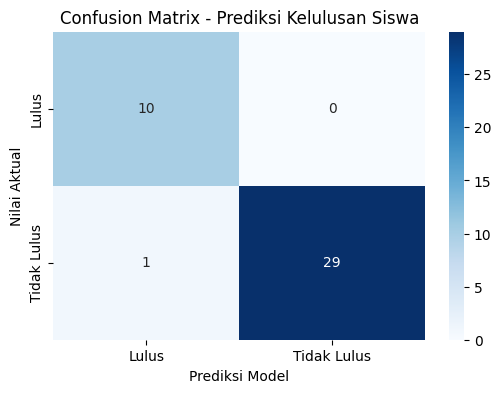

In [11]:
# Visualisasi Confusion Matrix dengan Seaborn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Confusion Matrix - Prediksi Kelulusan Siswa')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.show()

In [12]:
# Pengujian 3 Sampel Data Baru
sampel_baru = pd.DataFrame([
    {'Nilai_Tugas': 88, 'Nilai_UTS': 82, 'Nilai_UAS': 90, 'Persentase_Kehadiran': 95, 'Jumlah_Absen': 1}, # Ekspektasi: Lulus
    {'Nilai_Tugas': 50, 'Nilai_UTS': 40, 'Nilai_UAS': 55, 'Persentase_Kehadiran': 60, 'Jumlah_Absen': 9}, # Ekspektasi: Tidak Lulus
    {'Nilai_Tugas': 72, 'Nilai_UTS': 70, 'Nilai_UAS': 75, 'Persentase_Kehadiran': 85, 'Jumlah_Absen': 3}  # Ekspektasi: Lulus
])

prediksi = model.predict(sampel_baru)
probabilitas = model.predict_proba(sampel_baru)

# Membuat DataFrame Hasil Prediksi
df_hasil = sampel_baru.copy()
df_hasil['Hasil_Prediksi'] = prediksi
df_hasil['Probabilitas_Lulus (%)'] = [f"{p[list(model.classes_).index('Lulus')]*100:.1f}%" for p in probabilitas]
df_hasil['Probabilitas_Tidak_Lulus (%)'] = [f"{p[list(model.classes_).index('Tidak Lulus')]*100:.1f}%" for p in probabilitas]

print("=== HASIL PENGUJIANSAMPEL DATA BARU ===")
display(df_hasil)

=== HASIL PENGUJIANSAMPEL DATA BARU ===


,Nilai_Tugas,Nilai_UTS,Nilai_UAS,Persentase_Kehadiran,Jumlah_Absen,Hasil_Prediksi,Probabilitas_Lulus (%),Probabilitas_Tidak_Lulus (%)
0,88,82,90,95,1,Lulus,95.0%,5.0%
1,50,40,55,60,9,Tidak Lulus,1.0%,99.0%
2,72,70,75,85,3,Lulus,92.0%,8.0%


In [14]:
# Simpan Model
filename = 'model_kelulusan.pkl'
with open(filename, 'wb') as file:
    pickle.dump(model, file)

print(f"✓ Model berhasil disimpan sebagai '{filename}'")

# Mengunduh file model di Colab
files.download('model_kelulusan.pkl')


✓ Model berhasil disimpan sebagai 'model_kelulusan.pkl'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>